## **Introduction**

This is a supervised, binary classification problem.

The objective is to predict whether the patient has diabetes or not, based on the diagnostic measurements given.



In [ ]:
# Import libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV


In [ ]:
# Load dataset

df = pd.read_csv('/content/diabetes.csv')

# Data Inspection

df.head()
df.tail()
df.shape
df.columns
df.dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               2000 non-null   int64  
 1   Glucose                   2000 non-null   int64  
 2   BloodPressure             2000 non-null   int64  
 3   SkinThickness             2000 non-null   int64  
 4   Insulin                   2000 non-null   int64  
 5   BMI                       2000 non-null   float64
 6   DiabetesPedigreeFunction  2000 non-null   float64
 7   Age                       2000 non-null   int64  
 8   Outcome                   2000 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 140.8 KB


In this data, there are 9 columns labeled as: Pregnancies, Glucose, Blood Pressure, Skin Thickness, Insulin, BMI, Diabetes Pedigree Function, Age and Outcome, with 2000 non-null values.

In [ ]:
# Summary

df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.703500,121.182500,69.145500,20.935000,80.254000,32.193000,0.470930,33.090500,0.342000
std,3.306063,32.068636,19.188315,16.103243,111.180534,8.149901,0.323553,11.786423,0.474498
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,63.500000,0.000000,0.000000,27.375000,0.244000,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,40.000000,32.300000,0.376000,29.000000,0.000000
75%,6.000000,141.000000,80.000000,32.000000,130.000000,36.800000,0.624000,40.000000,1.000000
max,17.000000,199.000000,122.000000,110.000000,744.000000,80.600000,2.420000,81.000000,1.000000


This summary provides us a quick overview of the numeric columns in the dataset, which helps us to understand the distribution of key variables.

In [ ]:
# Check missing values

df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


There are no null/missing values.

In [ ]:
# Check duplicate value

df.duplicated().sum()

np.int64(1256)

There are 1,256 rows in the dataset, that are duplicates of previous rows.

In [ ]:
# Cleaning data by standardizing formats
df_clean = df.drop_duplicates().copy()

# Displaying the DataFrame after cleaning
print("DataFrame after cleaning data by standardizing formats:")
print(df)

DataFrame after cleaning data by standardizing formats:
      Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0               2      138             62             35        0  33.6   
1               0       84             82             31      125  38.2   
2               0      145              0              0        0  44.2   
3               0      135             68             42      250  42.3   
4               1      139             62             41      480  40.7   
...           ...      ...            ...            ...      ...   ...   
1995            2       75             64             24       55  29.7   
1996            8      179             72             42      130  32.7   
1997            6       85             78              0        0  31.2   
1998            0      129            110             46      130  67.1   
1999            2       81             72             15       76  30.1   

      DiabetesPedigreeFunction  Age  Outcom

The dataset contains 2000 patient records with 9 categories.

The categories include influencing factors, which are pregnancies, glucose, blood pressure, skin thickness, insulin, BMI, age, diabetes pedigree function; which can help us to predict the presence or absence of diabetes.

The outcome is the target variable. It contains binary values:

0: Absence of Diabetes

1: Presence of Diabetes

After cleaning and standardizing the data, it is well-prepared for exploratory analysis and binary classification.

   

## **Exploratory Data Analysis**

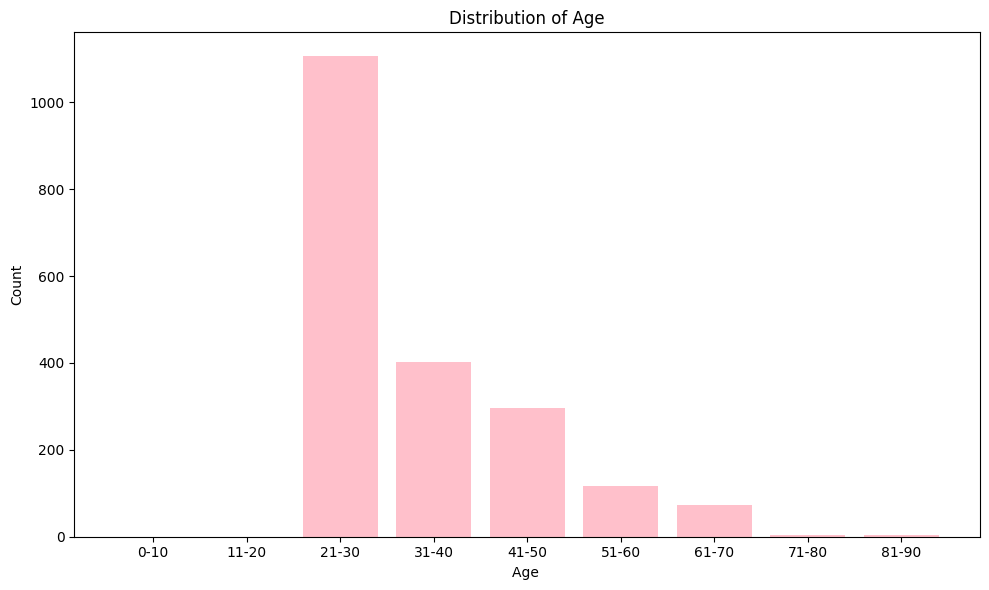

In [ ]:
# Distribution of Age

bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]

labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71-80', '81-90']

age_binned = pd.cut(df['Age'], bins=bins, labels=labels, right=True, include_lowest=True)

counts_per_bin = age_binned.value_counts().sort_index()

# Plotting the bar chart
plt.figure(figsize=(10, 6))
plt.bar(counts_per_bin.index, counts_per_bin.values, color='pink')
plt.title('Distribution of Age')
plt.xlabel('Age ')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In the bar graph showing distribution of age, the x-axis represents the age and the y-axis represents the count of patients.

There are >1000 patients belonging to the age group of 21-30 years. There are ~400 patients in the age group of 31-40 years. There are ~300 patients in the age group of 41-50 years. There are less than 100 patients in the age group of 51-60, 61-70, 71-80 and 81-90 years.

Maximum number of patients lies in the age group of 21-30 years. The number of patients decreases as the age increases.

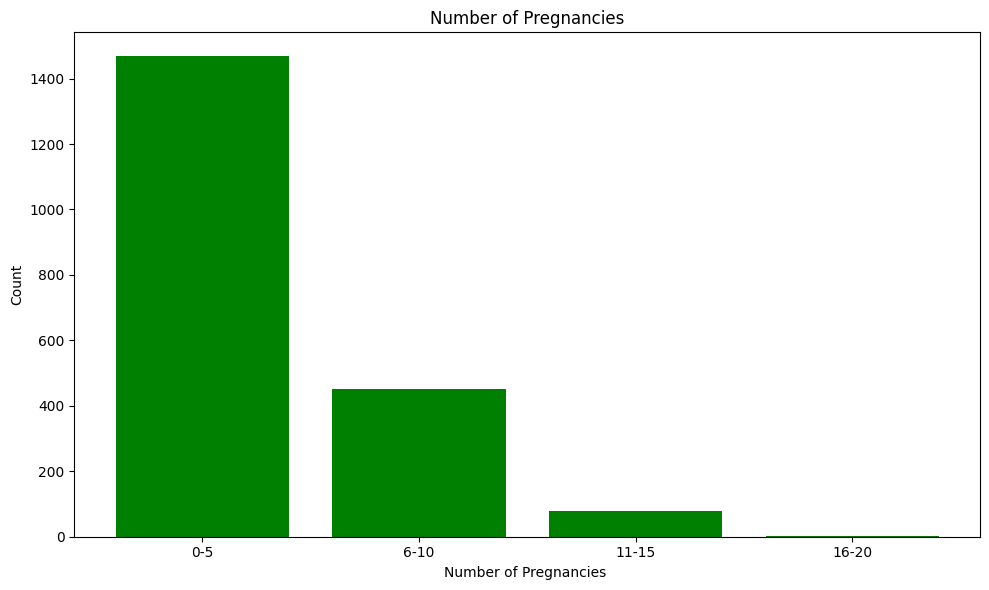

In [ ]:
# Number of Pregnancies

bins = [0, 5, 10, 15, 20]

labels = ['0-5', '6-10', '11-15', '16-20']

pregnancies_binned = pd.cut(df['Pregnancies'], bins=bins, labels=labels, right=True, include_lowest=True)

counts_per_bin = pregnancies_binned.value_counts().sort_index()

# Plotting the bar chart
plt.figure(figsize=(10, 6))
plt.bar(counts_per_bin.index, counts_per_bin.values, color='green')
plt.title('Number of Pregnancies')
plt.xlabel('Number of Pregnancies ')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

This bar graph shows number of pregnancies. The x-axis represents the number of pregnancies and the y-axis represents the number of patients.

More than 1400 patients have had 0-5 pregnancies. ~450 patients have had 6-10 pregnancies. ~50 patients have had 11-15 pregnancies and less than 10 patients had 16-20 pregnancies.

Maximum number of paients had 0-5 pregnancies. As the number of pregnancies increases the number of patient decreases.

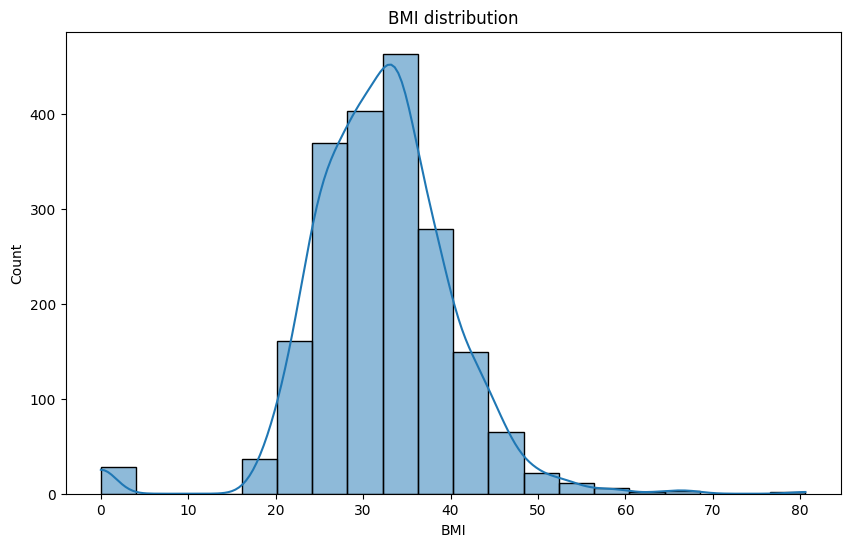

In [ ]:
# Distribution of BMI

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['BMI'], bins=20, kde=True)
plt.title('BMI distribution')
plt.xlabel('BMI')
plt.ylabel('Count')
plt.show()

This histoplot shows the distribution of BMI Index.

The KDE Curve has one peak, which means most observations are concentrated around the central value. The data has low variability.

Maximum number of patients have BMI of ~30-40.

The chart shows significant number of patients with BMI index of 0, which is physiologically not possible and will be considered as missing values in the future steps.

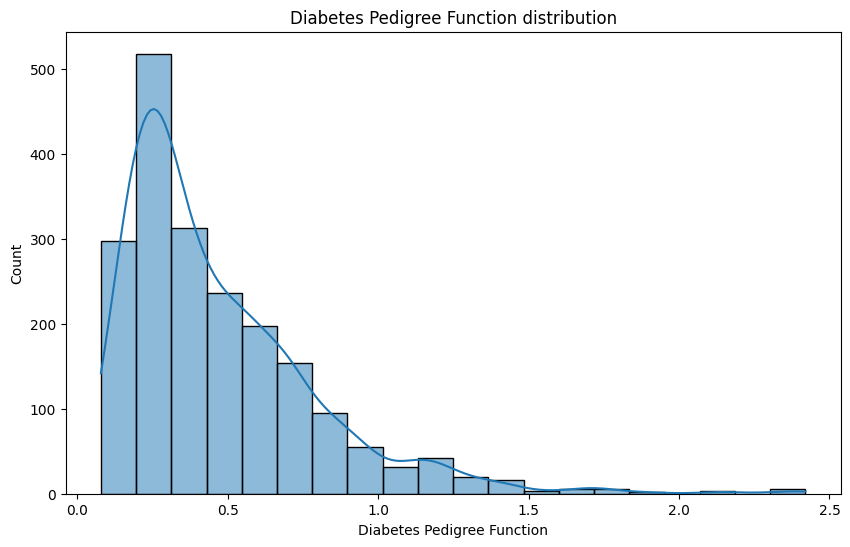

In [ ]:
# Distribution of Diabetes Pedigree Function

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['DiabetesPedigreeFunction'], bins=20, kde=True)
plt.title('Diabetes Pedigree Function distribution')
plt.xlabel('Diabetes Pedigree Function')
plt.ylabel('Count')
plt.show()

This histoplot shows the distribution of Diabetes pedigree function. Daibetes pedigree function shows the likelihood of diabetes based on family history. The x-axis represents the diabetes pedigree function values and y-axis represents the number of patients.

KDE Curve is unimodal, so most observations are centered around one value. It has long tail to the right i.e. it is right skewed(positively skewed).

More than 500 patients have diabetes pedigree value of ~0.2.

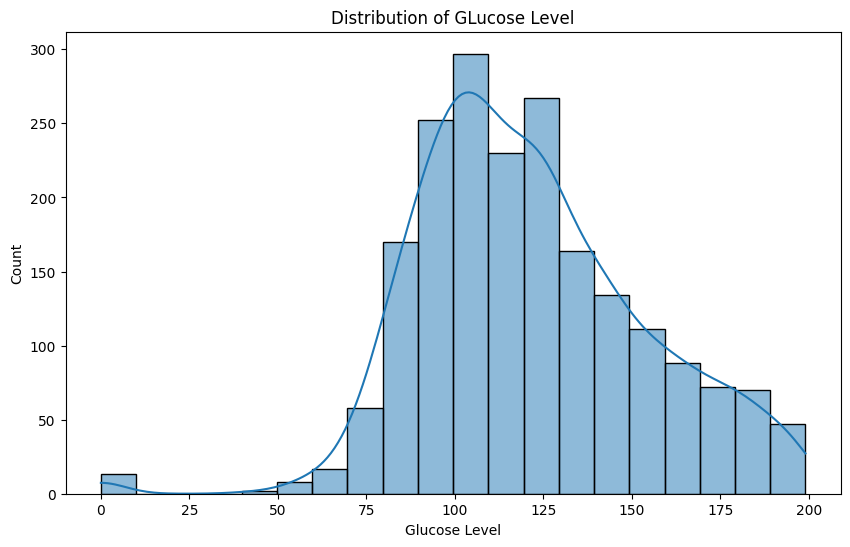

In [ ]:
# Distribution of Glucose Level

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['Glucose'], bins=20, kde=True)
plt.title('Distribution of GLucose Level')
plt.xlabel('Glucose Level')
plt.ylabel('Count')
plt.show()

This histoplot shows the distribution of glucose level. The x-axis represents the glucose level and y-axis represents the number of patients.

The KDE curve is wide, i.e. data is more spread out with high variability. ~300 patients have glucose level of 100 and, >250 patients have glucose level of 125. The curve is slightly skewed to the left, it means it is negatively skewed.

There are few number of patients who have glucose level as 0, which is physiologically impossible.

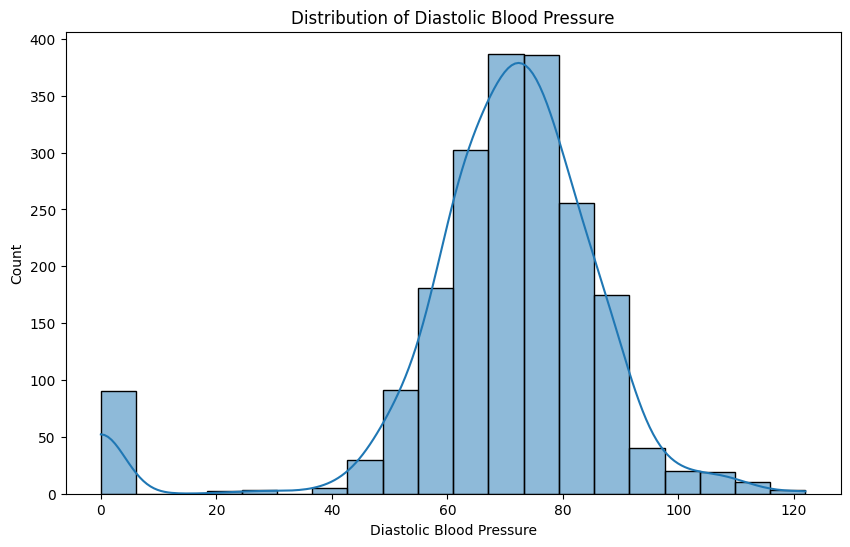

In [ ]:
# Distribution of Diastolic Blood Pressure

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['BloodPressure'], bins=20, kde=True)
plt.title('Distribution of Diastolic Blood Pressure')
plt.xlabel('Diastolic Blood Pressure')
plt.ylabel('Count')
plt.show()

The histoplot shows the distribution of Diastolic Blood Pressure. The x-axis represents the diastolic blood pressure and the y-axis represents the number of patients.

The KDE Curve is unimodal, i.e. most of the values are concentrated around one value. 350-400 patients have diastolic blood pressure between 60-80 mmHg. The curve is negatively skewed.

Number of patients show the diastolic blood pressure value of 0, which is physiologically impossible.

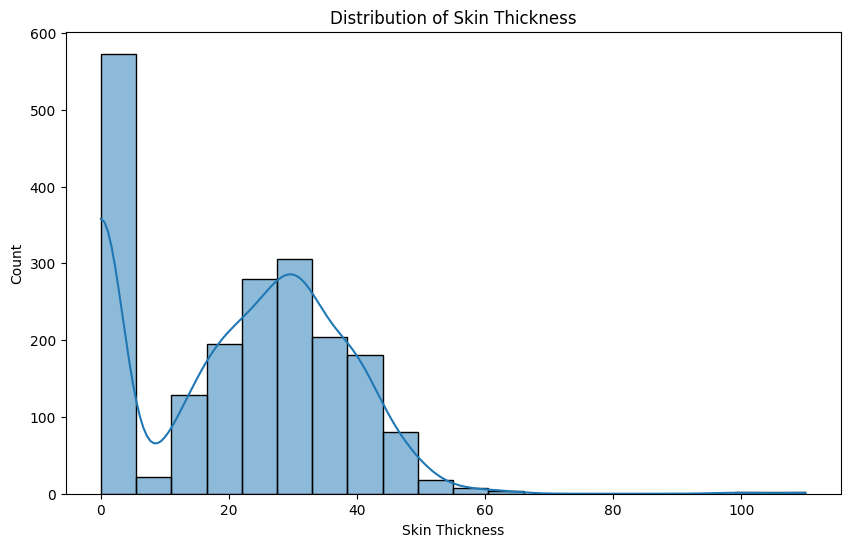

In [ ]:
# Distribution of Skin Thickness

fig = plt.figure(figsize=(10, 6))
sns.histplot(df['SkinThickness'], bins=20, kde=True)
plt.title('Distribution of Skin Thickness')
plt.xlabel('Skin Thickness')
plt.ylabel('Count')
plt.show()


This histoplot shows the distribution of skin thicknes. Skin thickness shows connective tissue changes in diabetes. The x-axis represents the skin thickness and the y-axis represents the number of patients.

The KDE Curve is wide, which shows the data is spread over a wide range and has high variability. ~300 patients show the skin thickness of ~30.

A significant number of patients show skin thickness of 0 value which is medically not relevant.

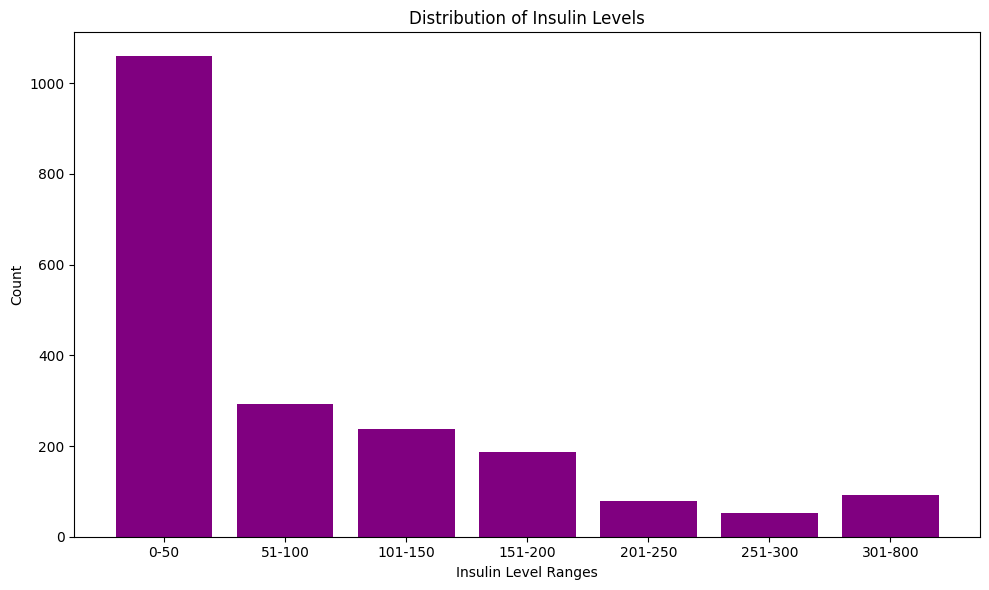

In [ ]:
# Insulin Level

bins = [0, 50, 100, 150, 200, 250, 300, 800]

labels = ['0-50', '51-100', '101-150', '151-200', '201-250', '251-300', '301-800']

insulin_binned = pd.cut(df['Insulin'], bins=bins, labels=labels, right=True, include_lowest=True)

counts_per_bin = insulin_binned.value_counts().sort_index()

# Plotting the bar chart
plt.figure(figsize=(10, 6))
plt.bar(counts_per_bin.index, counts_per_bin.values, color='purple')
plt.title('Distribution of Insulin Levels')
plt.xlabel('Insulin Level Ranges')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

The bar graph shows the ranges of insulin level. The x-axis indicates insulin level and the y-axis represents the number of patients.

More than 1000 patients have insulin level of 0-50 and least number of patients have insulin level of 251-300.

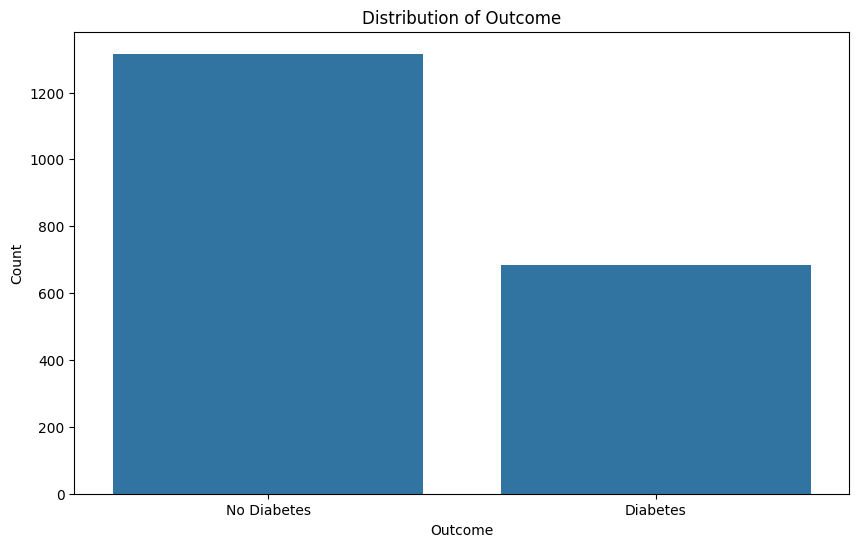

In [ ]:
# Distribution of Outcome

fig = plt.figure(figsize=(10, 6))
ax = sns.countplot(x='Outcome', data=df)
ax.set_xticks([0, 1])
ax.set_xticklabels(['No Diabetes', 'Diabetes'])

plt.title('Distribution of Outcome')
plt.xlabel('Outcome')
plt.ylabel('Count')

plt.show()

The bar graph represents the target variable indicated as Outcome. This shows whether the patient has diabetes or not. The x-axis is represented by outcome and the y-axis represents the number of patients.

The variable 0 is indicated as No diabetes and variable 1 is indicated as diabetes.

More than 1200 patients do not have diabetes and ~700 patients have diabetes. There is a significant difference in the presence and absence of diabetes. the target variable will be used to check the relationship with other categories.

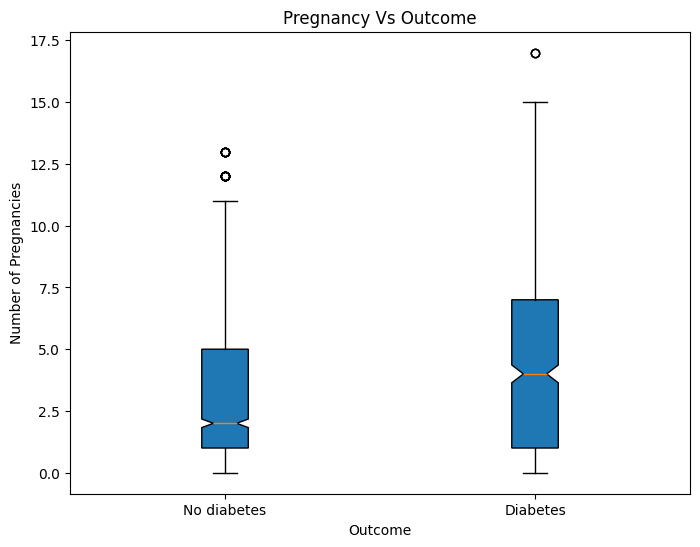

In [ ]:
# Pregnancy Vs Outcome

# Group the actual pregnancies data by the outcome classes
group_no_diabetes = df[df['Outcome'] == 0]['Pregnancies']
group_diabetes = df[df['Outcome'] == 1]['Pregnancies']

data = [group_no_diabetes, group_diabetes]

plt.figure(figsize=(8, 6))
plt.boxplot(data, tick_labels=['No diabetes', 'Diabetes'], patch_artist=True, notch=True)

plt.xlabel('Outcome')
plt.ylabel('Number of Pregnancies')
plt.title('Pregnancy Vs Outcome')

plt.show()

This boxplot shows the relationship between pregnancy and outcome. The x-axis represents the outcome and the y-axis represents the number of pregnancies.

Firstly, in the No diabetes category, the first quartile(Q1) lies at ~5 and the third quartile(Q3) lies at about 1. The median lies at ~2. This means 25% of values are below 5, 50% of values are below 2 and 75% of value are below 1. Lower whisker is at 0 and the upper whisker is at ~11, showing most value ranges from 0-11. There are 2 outliers at ~12.25 and ~12.75 indicating these are unusually high in comparison to the rest.

Secondly, in the diabetes category, the first quartile(Q1) lies at ~7 and the third quartile(Q3) lies at about 1. The median lies at ~4.5. This means 25% of values are below 7, 50% of values are below 4.5 and 75% of value are below 1. Lower whisker is at 0 and the upper whisker is at ~15, showing most value ranges from 0-15. There is 1 outlier at ~17, indicating this is unusually high in comparison to the rest.

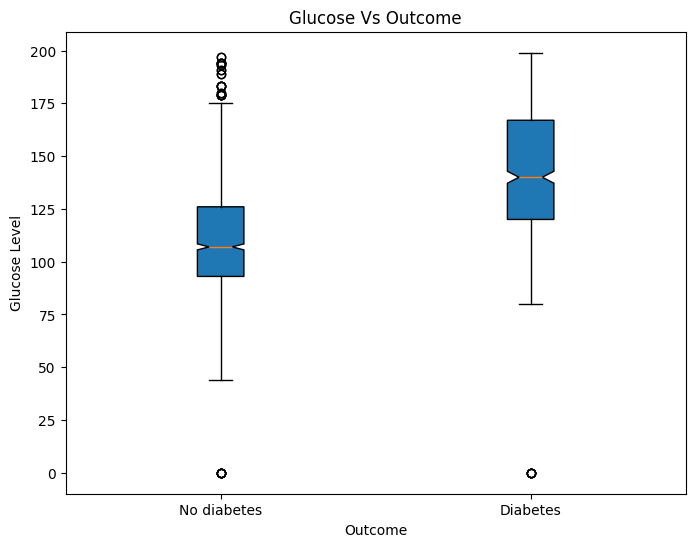

In [ ]:
# Glucose Vs Outcome

# Group the Glucose data by the outcome classes
group_no_diabetes = df[df['Outcome'] == 0]['Glucose']
group_diabetes = df[df['Outcome'] == 1]['Glucose']

data = [group_no_diabetes, group_diabetes]

plt.figure(figsize=(8, 6))
plt.boxplot(data, tick_labels=['No diabetes', 'Diabetes'], patch_artist=True, notch=True)

plt.xlabel('Outcome')
plt.ylabel('Glucose Level')
plt.title('Glucose Vs Outcome')

plt.show()

This boxplot shows the relationship between glucose and outcome. The x-axis represents the outcome and the y-axis represents the glucose level.

Firstly, in the No diabetes category, the first quartile(Q1) lies at ~125 and the third quartile(Q3) lies at about 90. The median lies at ~105. This means 25% of values are below 125, 50% of values are below 105 and 75% of value are below 90. Lower whisker is at ~45 and the upper whisker is at ~175, showing most value ranges from 125-175. There is 1 outlier at 0 and a significant number of outliers above 175, indicating these are unusually high in comparison to the rest.

Secondly, in the diabetes category, the first quartile(Q1) lies at ~170 and the third quartile(Q3) lies at about 125. The median lies at ~145. This means 25% of values are below 170, 50% of values are below 145 and 75% of value are below 125. Lower whisker is at 75 and the upper whisker is at 200, showing most value ranges from 200-75. There is 1 outlier at 0, indicating this is unusually high in comparison to the rest.

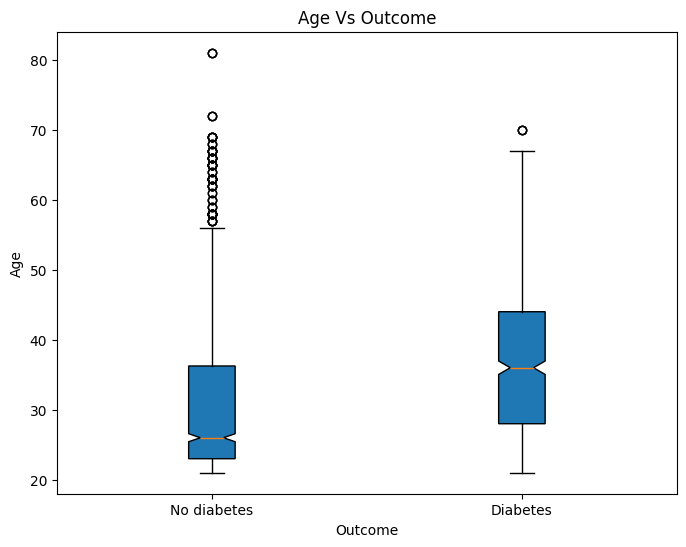

In [ ]:
# Age Vs Outcome

# Group the age data by the outcome classes
group_no_diabetes = df[df['Outcome'] == 0]['Age']
group_diabetes = df[df['Outcome'] == 1]['Age']

data = [group_no_diabetes, group_diabetes]

plt.figure(figsize=(8, 6))
plt.boxplot(data, tick_labels=['No diabetes', 'Diabetes'], patch_artist=True, notch=True)

plt.xlabel('Outcome')
plt.ylabel('Age')
plt.title('Age Vs Outcome')

plt.show()

This boxplot shows the relationship between age and outcome. The x-axis represents the outcome and the y-axis represents the age.

Firstly, in the No diabetes category, the first quartile(Q1) lies at ~36 and the third quartile(Q3) lies at about ~24. The median lies at ~25. This means 25% of values are below 36, 50% of values are below 25 and 75% of value are below 24. Lower whisker is at 21 and the upper whisker is at ~55, showing most value ranges from 21-55. There are significant numbers of outliers above 55, indicating these are unusually high in comparison to the rest.

Secondly, in the diabetes category, the first quartile(Q1) lies at ~42 and the third quartile(Q3) lies at about 29. The median lies at ~38. This means 25% of values are below 42, 50% of values are below 38, and 75% of value are below 29. Lower whisker is at 21 and the upper whisker is at 65, showing most value ranges from 21-65. There is 1 outlier at 65, indicating this is unusually high in comparison to the rest.

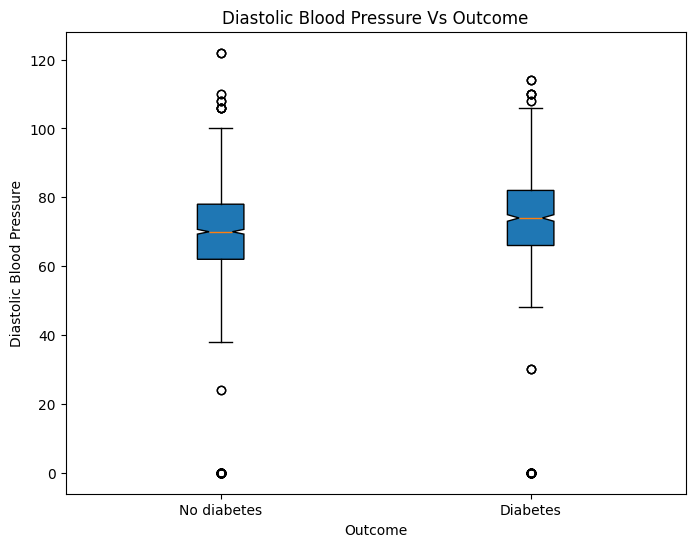

In [ ]:
# Blood Pressure Vs Outcome

# Group the blood pressure data by the outcome classes
group_no_diabetes = df[df['Outcome'] == 0]['BloodPressure']
group_diabetes = df[df['Outcome'] == 1]['BloodPressure']

data = [group_no_diabetes, group_diabetes]

plt.figure(figsize=(8, 6))
plt.boxplot(data, tick_labels=['No diabetes', 'Diabetes'], patch_artist=True, notch=True)

plt.xlabel('Outcome')
plt.ylabel('Diastolic Blood Pressure')
plt.title('Diastolic Blood Pressure Vs Outcome')

plt.show()


This boxplot shows the relationship between diastolic blood pressure and outcome. The x-axis represents the outcome and the y-axis represents the diastolic blood pressure.

Firstly, in the No diabetes category, the first quartile(Q1) lies at ~79 and the third quartile(Q3) lies at about 61. The median lies at ~70. This means 25% of values are below 79, 50% of values are below 70 and 75% of value are below 61. Lower whisker is at 40 and the upper whisker is at ~100, showing most value ranges from 40-100. There are 2 outliers below 40 and 4 outliers above 100, indicating these are unusually high in comparison to the rest.

Secondly, in the diabetes category, the first quartile(Q1) lies at ~81 and the third quartile(Q3) lies at about 65. The median lies at ~70. This means 25% of values are below 81, 50% of values are below 70, and 75% of value are below 65. Lower whisker is at 50 and the upper whisker is at ~105, showing most value ranges from 50-105. There is 2 outlier at 0 and ~45, and 3 outliers above 105, indicating this is unusually high in comparison to the rest.

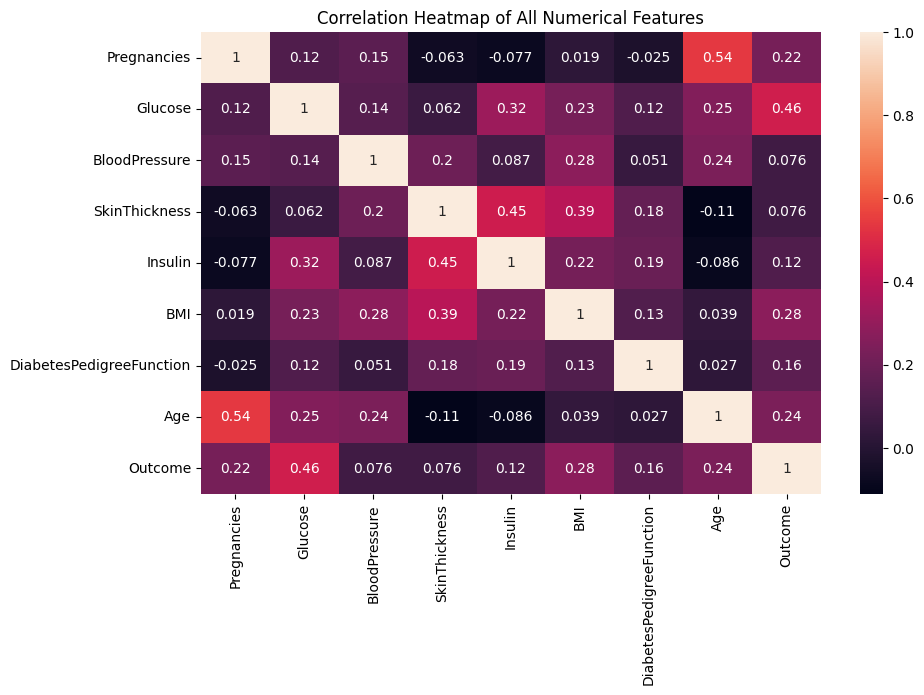

In [ ]:
# Correlation Heatmap of All Numerical Features

fig = plt.figure(figsize=(10, 6))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True)
plt.title('Correlation Heatmap of All Numerical Features')
plt.show()

The correlation heatmap, shows the strength and direction of the relationship between numerical values of all the categories.

There is moderate positive correlation between; age and pregnancy, glucose and the outcome, insulin and skin thickness, glucose and insulin, skin thickness and BMI. This means they have moderate positive relationship with each other.

There is a weak positive correlation between; age and glusoce, pregancy and the outcome, skin thickness and blood pressure, BMI and blood pressure, age and blood pressure, BMI and insulin, BMI and the outcome. A weaker positive correlation can be seen of pregnancy with glucose, blood pressure and the outcome; blood pressure with the outcome, diabetes pedigree function, insulin, and pregnancy; skin thickness with outcome, and diabetes pedigree function; insulin with outcome, diabetes pedigree function; BMI with age, diabetes pedigree function and pregnancy; diabetes pedigree function with outcome, age, BMI. That means they have little positive relationship with each other.

A weak correlation can be seen of pregnancy with diabetes pedigree function, insulin and skin thickness; skin thickness with age; and insulin with age. That means they have little negative relation with each other.



**After exploratory data analysis**, we can see that categories such as BMI, glucose level, blood pressure, skin thickness and insulin level have values of 0, which is physiologically not possible.

So we can make out 0 means missing/unrecorded values.

The affected columns have numerical values. Several of them can be skewed and/or contain outliers. The median is less affected by outliers, so it is a better method to handle these missing/unrecorded values.

**Consideration:** It is better not to calculate the median using the entire dataset before train-test splitting because, the information from the test set might influence preprocessing and lead to data leakage. Hence, we will replace the missing values with NaN first, then do train-test splitting. After that, we will calculate median value using training data only.

## **Data Preprocessing**

In [ ]:
# Checking number of zero values
df[['Glucose', 'BMI', 'BloodPressure', 'SkinThickness', 'Insulin']].eq(0).sum()

,0
Glucose,13
BMI,28
BloodPressure,90
SkinThickness,573
Insulin,956


We have checked the number of zeroes these categories contain, and we can see that insulin has 956 zeros, skin thickness has 573, blood pressure has 90, BMI has 28 and glucose has 13. Insulin has maximum number of "0" variables.

In [ ]:
# Replace zeros with NaN
cols = ['Glucose', 'BMI', 'BloodPressure', 'SkinThickness', 'Insulin']

df[cols] = df[cols].replace(0, np.nan)

# Check NaN
print("\nNaN after replacement:")
print(df[cols].isna().sum())


NaN after replacement:
Glucose           13
BMI               28
BloodPressure     90
SkinThickness    573
Insulin          956
dtype: int64


All the "0" variables were replaced with NaN.

In [ ]:
df_clean = df.drop_duplicates().copy()

cols = ['Glucose', 'BMI', 'BloodPressure',
        'SkinThickness', 'Insulin']

df_clean[cols] = df_clean[cols].replace(0, np.nan)

The clean data is now used for train-test split.

## **Train-Test Split**

In [ ]:
# Separate features and target variable using 'Outcome'
df_clean = df.drop_duplicates().copy()
X = df_clean.drop(['Outcome'], axis=1)
y = df_clean['Outcome']

# Split dataset into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (595, 8)
X_test shape: (149, 8)
y_train shape: (595,)
y_test shape: (149,)


There are 595 training samples each with 8 features.
There are 149 testing samples each with 8 features.
There are 595 training labels, one for each training sample.
There are 149 testing labels, one for each testing sample.

## **Training ML models**

In [ ]:
# 1.Logistic Regression

from sklearn.model_selection import cross_val_score
# Define the pipeline
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('log_reg', LogisticRegression(max_iter=10000, random_state=42))
])

# Fit the pipeline on the training data
pipeline.fit(X_train, y_train)

# Predict on the training set
y_pred_train_log_reg = pipeline.predict(X_train)

# Calculate the training accuracy
training_accuracy = accuracy_score(y_train, y_pred_train_log_reg)

# Cross-Validation
scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Mean CV Accuracy:", scores.mean())


Mean CV Accuracy: 0.7546218487394959


The accuracy score for logistic regression is 0.754.

In [ ]:
# 2.Decision Tree

# Define the pipeline
Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(random_state=42))
])

dt_model = DecisionTreeClassifier(random_state=42)

scores_dt = cross_val_score(
    dt_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Decision Tree CV Accuracy:", scores_dt.mean())


Decision Tree CV Accuracy: 0.7243697478991598


The accuracy score for decision tree is 0.724.

In [ ]:
# 3.Random Forest

# Define the pipeline
Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(random_state=42))
])
rf_model = RandomForestClassifier(random_state=42)

scores_rf = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Random Forest CV Accuracy:", scores_rf.mean())

Random Forest CV Accuracy: 0.7445378151260504


The random forest accuracy score is 0.744.

In [ ]:
# 4.XG Boost

# Define the pipeline
Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(random_state=42))
])
rf_model = XGBClassifier(random_state=42)

scores_rf = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("XG Boost CV Accuracy:", scores_rf.mean())

XG Boost CV Accuracy: 0.7361344537815127


THe accuracy score for XG Boost is 0.736.

### **Compare models using Cross-Validation**

In [ ]:
# Model comparison using cross-validation

models = {
    "Logistic Regression": pipeline,
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="f1"
    )

    print(name, "Mean F1:", scores.mean())

Logistic Regression Mean F1: 0.602766591428489
Decision Tree Mean F1: 0.5905520738349139
Random Forest Mean F1: 0.5885778635778636
XGBoost Mean F1: 0.6085157865979783


XGBoost has the highest mean F1 score of 0.608. Hence, we will tune the XGBoost model.

Between accuracy score and F1 score, we choose F1 score for hyperparameter tuning because accuracy score only checks how many predictions the model overall got correct. Whereas, the F1 score balances precision and recall. Precision checks from the people predicted as diabetic, how many actually are diabetic. While, recall checks the number of patients we identified as diabetic from the people who actually have diabetes.

## **Hyperparameter Tuning**

In [ ]:
# Hyperparameter tuning for XGBoost

xgb = XGBClassifier(random_state=42)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Gridsearch CV

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(grid_search.best_params_)

best_rf = grid_search.best_estimator_

final_model = grid_search.best_estimator_

{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}


The random forest built 200 decision trees, allowed them to grow without a fixed depth limit, allowing splitting with as few as 2 samples with minimum of 2 sample leaf.

## **Evaluation in the test set**

In [ ]:
# Classification Report

# Generate predictions on the test set using the best estimator from hyperparameter tuning
y_pred = final_model.predict(X_test)

# Print the evaluation report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.86      0.83        98
           1       0.69      0.61      0.65        51

    accuracy                           0.77       149
   macro avg       0.75      0.73      0.74       149
weighted avg       0.77      0.77      0.77       149



A classification report summarizes how well the classification model performed.

**Class 0: No diabetes**

Precision: 0.81

Of all the patients the model predicted as without diabetes, 81% were actually without diabetes.

Recall: 0.86

Out of 98 patients without diabetes, the model correctly identified 86% of them.

F1-score: 0.83

The F1 score is 83%, indicating there is a good balance between recall and precision.

Support: 98

There were 98 actual patients without diabetes in the dataset.

**Class 1: Diabetes**

Precision: 0.69

Of all the patients predicted as patients with diabetes, 69% had diabetes.

Recall: 0.61

Out of 51 actual diabetic patients, the model correctly identified 61% of them.

F1-score: 0.65

The F1-score is 65%, indicating there is a less balance between recall and precision.

Support: 51

There were 51 actual patients with diabetes in the dataset.

**Accuracy: 0.77**

The model correctly classified 77% of all the test samples. That means, the model correctly identified approximately 114 samples correctly.

**Macro average:**

Macro average gives equal importance to every class. Here, the macro scores are:

Precision: 0.75

Recall: 0.73

F1-score: 0.74

**Weighted average**

Weighted average gives more importance to class with more samples. Here the weighted scores are:

Precision: 0.77

Recall: 0.77

F1-score: 0.77


[[84 14]
 [20 31]]


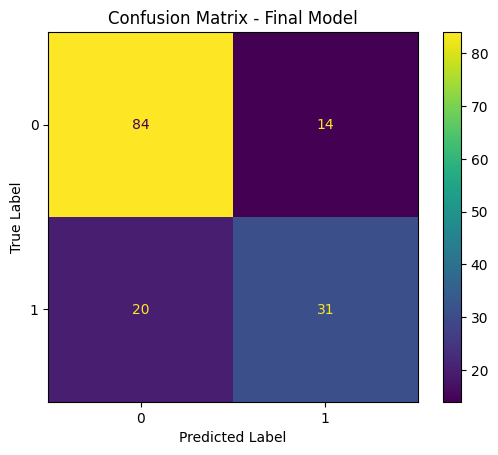

In [ ]:
# Confusion Matrix

# Make predictions using the final model
y_pred = final_model.predict(X_test)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

print(confusion_matrix(y_test, y_pred))

plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In this confusion matrix:

**True Negative(TN)**

Actual class = 0

Predicted class = 0

The model correctly predicted 84 non-diabetic patients.

**False Positive (FP)**

Actual class: 0

Predicted class: 1

The model incorrectly predicted 14 patients as diabetic patients.

**False Negative (FN)**

Actual class: 1

Predicted class: 0

The model incorrectly predicted 20 patients as non-diabetic.

**True Positive (TP)**

Actual class: 1

Predicted class: 1

The model correctly identified 31 diabetic patients.


* The model only made 34 errors, indicating that the model performed well on the test data.

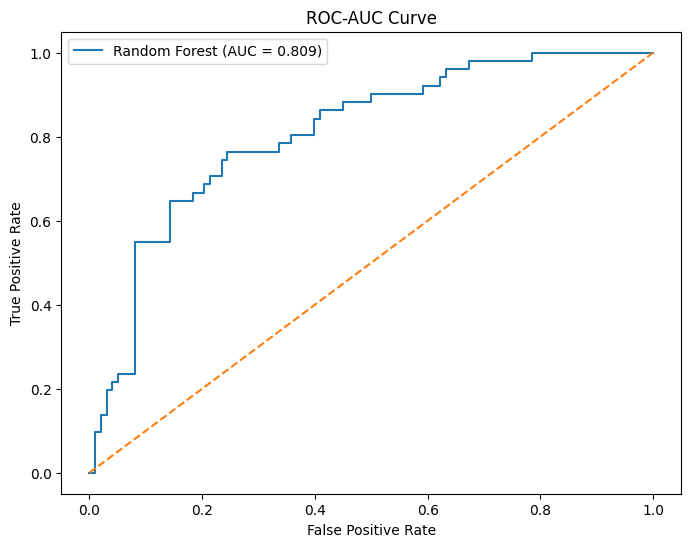

In [ ]:
# ROC-AUC Curve

y_prob_rf = final_model.predict_proba(X_test)[:, 1]

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curve")
plt.legend()
plt.show()

The ROC-AUC Curve shows the trade off between True positive rate and False positive rate.

The ROC-AUC Curve is above the diagonal and curved towards the left corner. AUC curve value is 0.809, indicating it is a good classifier. Thus, the model has a strong discrimination ability.

## **Finalizing the model**

In [ ]:
import pickle

# Save the final model to a file named final_model.pkl
with open('final_model.pkl', 'wb') as file:
    pickle.dump(final_model, file)

print("Model successfully saved to final_model.pkl")

Model successfully saved to final_model.pkl


After selecting and evaluating the final model, the trained model was successfully saved as final_model.pkl; so that it can be reused for future predictions without retraining.

## **CONCLUSION:**

Machine learning classification model was developed to predict the target outcome; i.e. whether the patient has diabetes or not, based on the given dataset.

The data was checked, cleaned and exploratory data analysis was done in the clean data. EDA showed that some categories had zero as variables, they were replaced with NaN and cleaned. Data preprocessing was done and the clean data was splitted using train-test method. The data was trained using models such as Logistic Regression, Decision Tree, Random Forest and XG Boost. After the models were compoared using cross-validation method, XGBoost model was selected as it had the highest mean F1-score of 0.608. Since, the dataset had class imbalance, mean F1-score was used for assessment rather than completely relying only on the accuracy score.

After the model selection, hyperparameter tuning was done and evaluation was done on the test set. The final model achieved 77% accuracy score and 71% of macro average score in the test set. The selected model only made 34 errors, indicating the model performed well on the dataset. The model showed strong discrimination ability in the ROC-AUC Curve. The final model was saved as final_model.pkl, such that it can be reused for future predictions without retraining.

This project showed how machine learning can be applied to the given binary classification dataset through data preprocessing, model training, evaluation of model and final model selection. Future improvements can be done by using methods like Feature engineering so that the model can learn the underlying pattern more effectively; SHAP can be used to identify the features that contributed most to the model predictions; better handling of class imbalance can be done with SMOTE technique; model deployment can be done to turn it into a real-world usable application.